# Batched Light Curve Demo

This notebook compares the original object-based light curve generation path with the JAX-native batched path. It uses five hard-coded representative self-lensing binary parameter sets and renders each light curve both ways.

The plotting cells require matplotlib, which is included in the project `demo` optional dependencies.

In [1]:
%matplotlib inline

import jax
import jax.numpy as jnp
import numpy as np
from astropy import units
from matplotlib import pyplot as plt

from selflensing.batch import batched_light_curve
from selflensing.generators import LightcurveGenerator
from selflensing.models import SelfLensingSystem

jax.config.update("jax_enable_x64", True)

Each row uses the public `SelfLensingSystem` units: `a` in AU, `i` and `periapsis_phase` in radians, masses in solar masses, companion radius in solar radii, and `Teff` in K.

In [2]:
systems = [
    {
        "name": "BH + solar companion",
        "a": 1.0,
        "i": 0.5 * np.pi - 0.00020,
        "Macc": 9.0,
        "Mcomp": 1.1,
        "Rcomp": 1.2,
        "Teff": 5800.0,
        "e": 0.20,
        "periapsis_phase": 0.40,
    },
    {
        "name": "Moderate eccentricity",
        "a": 1.3,
        "i": 0.5 * np.pi,
        "Macc": 7.0,
        "Mcomp": 1.4,
        "Rcomp": 1.5,
        "Teff": 6200.0,
        "e": 0.10,
        "periapsis_phase": 0.80,
    },
    {
        "name": "Massive accretor",
        "a": 2.2,
        "i": 0.5 * np.pi - 0.0015,
        "Macc": 18.0,
        "Mcomp": 1.8,
        "Rcomp": 1.7,
        "Teff": 7200.0,
        "e": 0.35,
        "periapsis_phase": 1.20,
    },
    {
        "name": "Compact orbit",
        "a": 0.55,
        "i": 0.5 * np.pi - 0.00040,
        "Macc": 5.5,
        "Mcomp": 0.9,
        "Rcomp": 0.9,
        "Teff": 5400.0,
        "e": 0.05,
        "periapsis_phase": 2.10,
    },
    {
        "name": "Warm companion",
        "a": 1.8,
        "i": 0.5 * np.pi - 0.00025,
        "Macc": 11.0,
        "Mcomp": 2.2,
        "Rcomp": 2.0,
        "Teff": 7800.0,
        "e": 0.45,
        "periapsis_phase": 2.80,
    },
]

times = np.linspace(-0.75, 0.75, 1200)
peak_times = np.zeros(len(systems))

## Original Generator Path

This is the existing object-oriented route. It constructs a `SelfLensingSystem` and a `LightcurveGenerator` for each parameter set.

In [3]:
def make_system(row):
    return SelfLensingSystem(
        a=row["a"] * units.au,
        i=row["i"] * units.rad,
        Macc=row["Macc"] * units.M_sun,
        Mcomp=row["Mcomp"] * units.M_sun,
        Rcomp=row["Rcomp"] * units.R_sun,
        Teff=row["Teff"] * units.K,
        e=row["e"] * units.dimensionless_unscaled,
        periapsis_phase=row["periapsis_phase"] * units.rad,
    )


old_fluxes = []
for row, peak_time in zip(systems, peak_times):
    generator = LightcurveGenerator(
        make_system(row),
        times=times,
        peak_time=peak_time,
        lensing_method="IntegratedWittMaoJax",
    )
    flux = generator.flux_array
    old_fluxes.append(np.asarray(flux.value if hasattr(flux, "value") else flux))

old_fluxes = np.stack(old_fluxes)

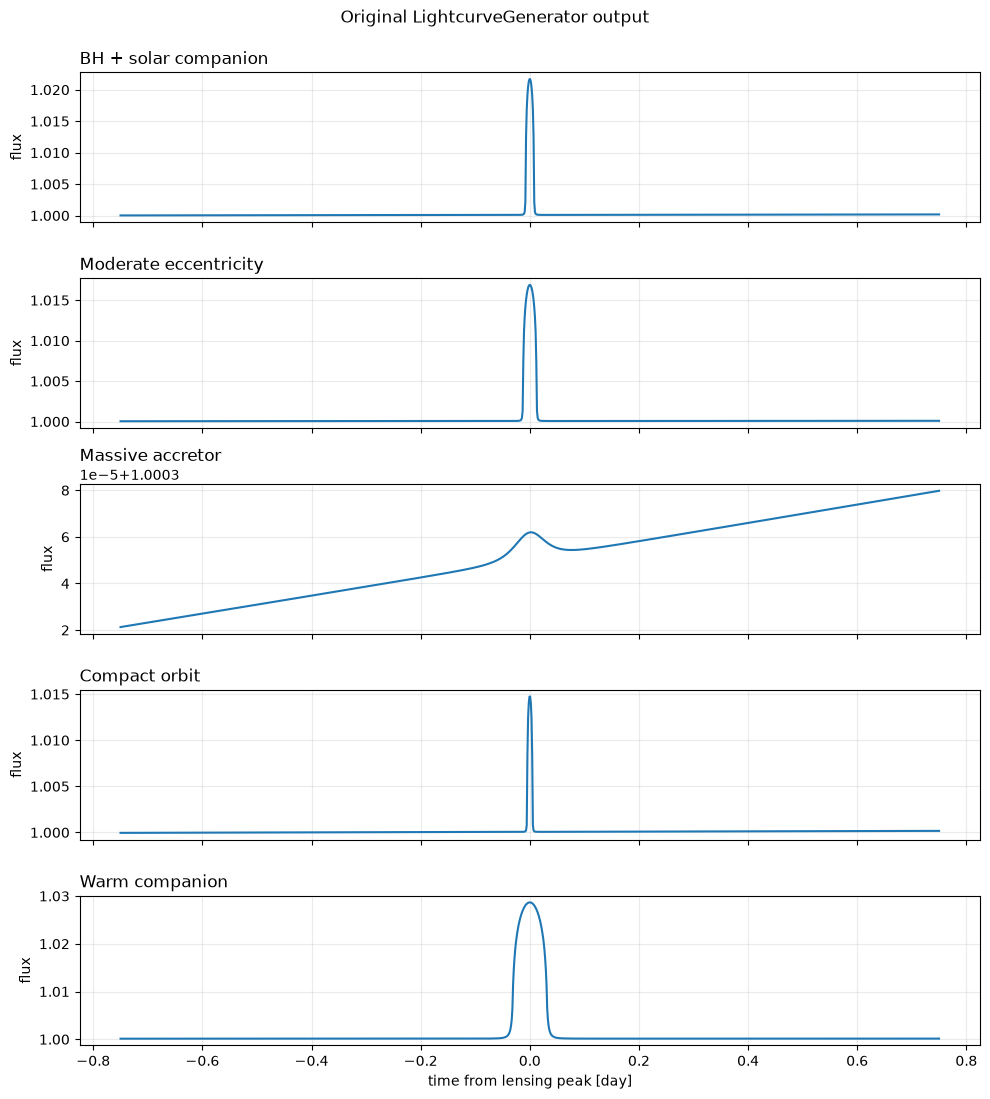

In [4]:
fig, axes = plt.subplots(len(systems), 1, figsize=(10, 11), sharex=True)

for ax, row, flux in zip(axes, systems, old_fluxes):
    ax.plot(times, flux, lw=1.5)
    ax.set_title(row["name"], loc="left")
    ax.set_ylabel("flux")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("time from lensing peak [day]")
fig.suptitle("Original LightcurveGenerator output", y=0.995)
fig.tight_layout()

## Batched Generator Path

This route sends all five parameter sets through one vectorized JAX call and returns a `(batch, n_times)` array.

In [5]:
batch_params = {
    key: jnp.asarray([row[key] for row in systems])
    for key in ["a", "i", "Macc", "Mcomp", "Rcomp", "Teff", "e", "periapsis_phase"]
}

batch_fluxes = np.asarray(
    batched_light_curve(
        jnp.asarray(times),
        batch_params,
        peak_times=jnp.asarray(peak_times),
    )
)

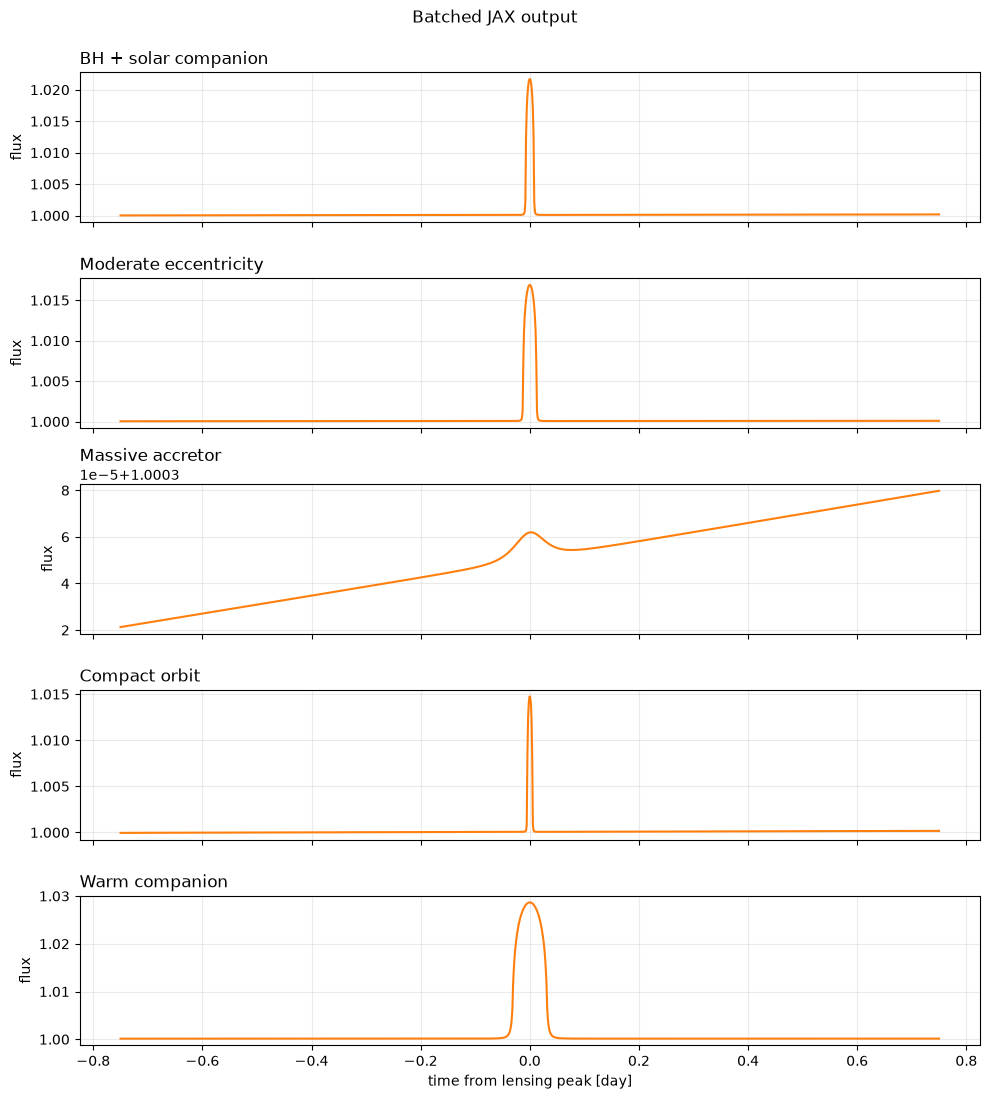

In [6]:
fig, axes = plt.subplots(len(systems), 1, figsize=(10, 11), sharex=True)

for ax, row, flux in zip(axes, systems, batch_fluxes):
    ax.plot(times, flux, lw=1.5, color="tab:orange")
    ax.set_title(row["name"], loc="left")
    ax.set_ylabel("flux")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("time from lensing peak [day]")
fig.suptitle("Batched JAX output", y=0.995)
fig.tight_layout()

## Agreement Check

In [7]:
max_abs_difference = np.max(np.abs(old_fluxes - batch_fluxes), axis=1)

for row, diff in zip(systems, max_abs_difference):
    print(f"{row['name']}: max |old - batch| = {diff:.3e}")

BH + solar companion: max |old - batch| = 0.000e+00
Moderate eccentricity: max |old - batch| = 0.000e+00
Massive accretor: max |old - batch| = 0.000e+00
Compact orbit: max |old - batch| = 0.000e+00
Warm companion: max |old - batch| = 0.000e+00


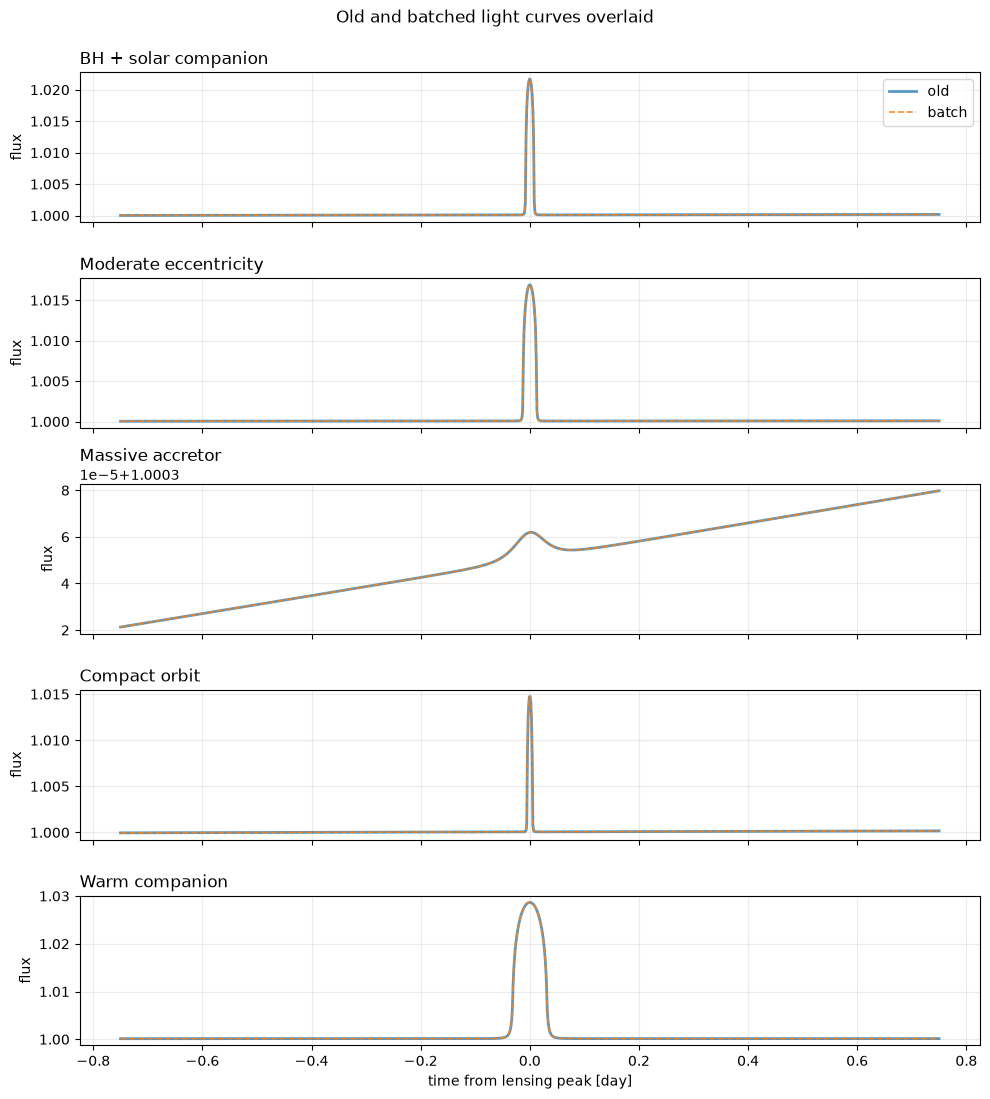

In [8]:
fig, axes = plt.subplots(len(systems), 1, figsize=(10, 11), sharex=True)

for ax, row, old_flux, batch_flux in zip(axes, systems, old_fluxes, batch_fluxes):
    ax.plot(times, old_flux, lw=2.0, label="old", alpha=0.75)
    ax.plot(times, batch_flux, lw=1.2, ls="--", label="batch", alpha=0.9)
    ax.set_title(row["name"], loc="left")
    ax.set_ylabel("flux")
    ax.grid(alpha=0.25)

axes[0].legend(loc="best")
axes[-1].set_xlabel("time from lensing peak [day]")
fig.suptitle("Old and batched light curves overlaid", y=0.995)
fig.tight_layout()